### 02. Скрытые факторы: что компенсирует плохие привычки? 

In [79]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd()).parent 
sys.path.insert(0, str(project_root))

from src.preparation import load_df
df = load_df()

,avg_social_media_hours,avg_netfix_hours,part_time_job_pct,good_diet_pct,frequent_exercise_pct,high_parental_education_level_pct,good_internet_quality_pct,avg_mental_health_rating,do_not_participate_in_extra_pct
group,,,,,,,,,
over_performing,1.796,1.270,22.794,37.500,44.118,15.504,36.029,8.118,61.029
underworking,3.168,2.291,23.288,39.726,15.068,21.805,49.315,2.795,66.438
rest,2.505,1.828,20.891,37.465,30.501,18.238,45.404,5.468,69.916


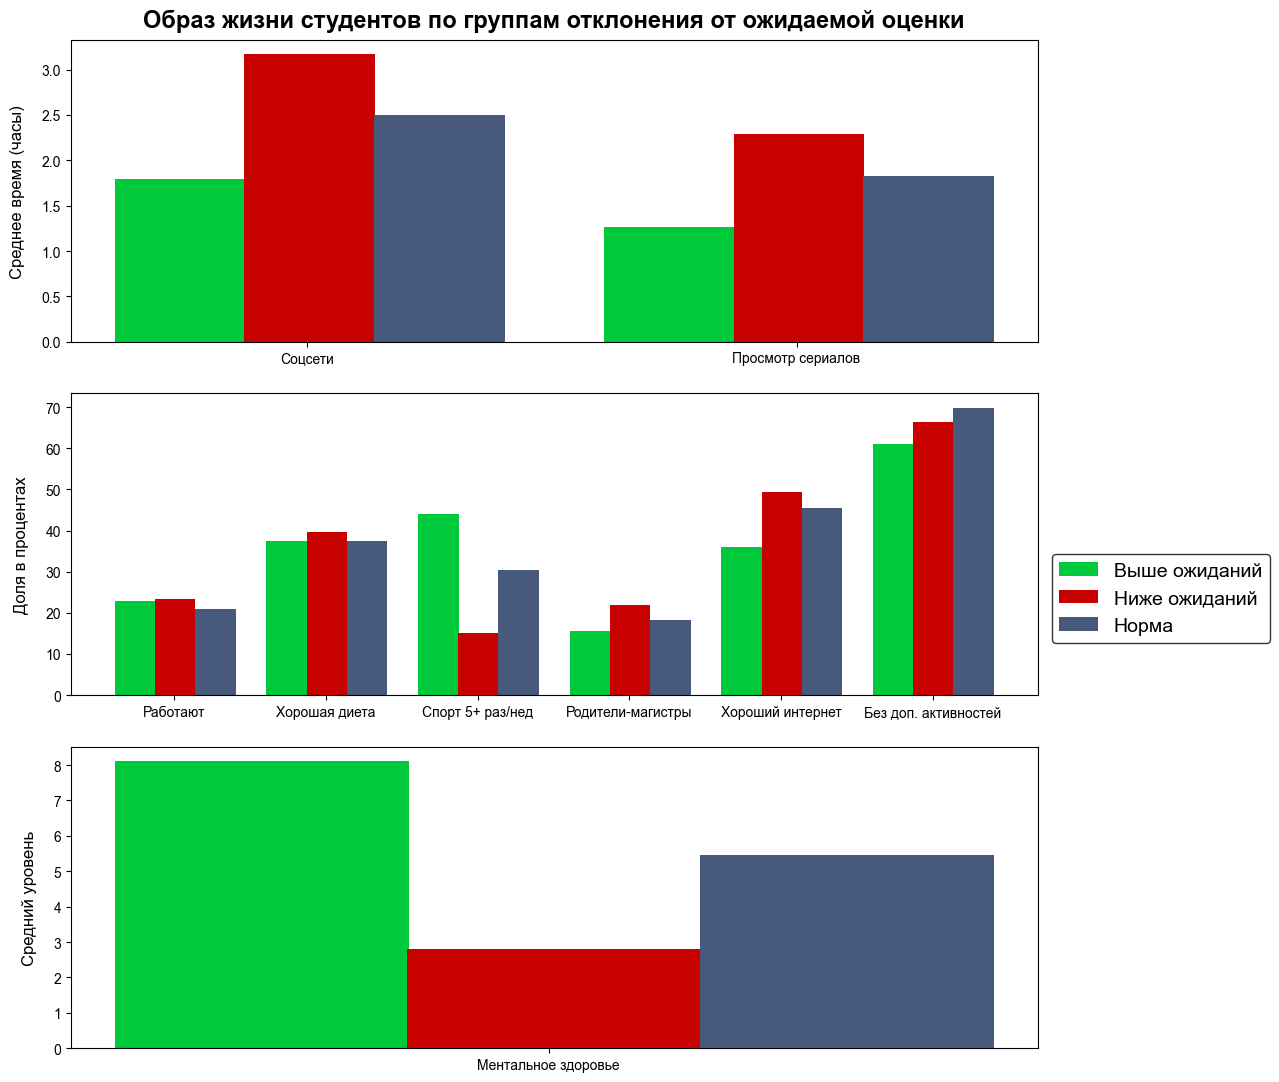

In [81]:
import matplotlib.pyplot as plt 
import numpy as np 
import src.constants as cnst 
from src.utils import bar_builder

plt.rcParams['font.family'] = 'Arial'

df_02_02 = df.copy()

# нормализация 3х мейн факторов 
df_02_02['study_hours_per_day_norm'] = (df_02_02.study_hours_per_day - df_02_02.study_hours_per_day.mean()) / df_02_02.study_hours_per_day.std()
df_02_02['attendance_percentage_norm'] = (df_02_02.attendance_percentage - df_02_02.attendance_percentage.mean()) / df_02_02.attendance_percentage.std()
df_02_02['sleep_hours_norm'] = (df_02_02.sleep_hours - df_02_02.sleep_hours.mean()) / df_02_02.sleep_hours.std()

# взвешивание каждого из мейн факторов по корреляции с exam_score 
df_02_02.study_hours_per_day_norm = df_02_02.study_hours_per_day_norm.corr(df_02_02.exam_score) * df_02_02.study_hours_per_day_norm
df_02_02.attendance_percentage_norm = df_02_02.attendance_percentage_norm.corr(df_02_02.exam_score) * df_02_02.attendance_percentage_norm
df_02_02.sleep_hours_norm = df_02_02.sleep_hours_norm.corr(df_02_02.exam_score) * df_02_02.sleep_hours_norm

# ожидаемая оценка + ее денормирование 
df_02_02['z_score'] = df_02_02.study_hours_per_day_norm + df_02_02.attendance_percentage_norm + df_02_02.sleep_hours_norm
df_02_02.z_score = df_02_02.z_score * df_02_02.exam_score.std() + df_02_02.exam_score.mean()

# реальная оценка - ожидаемая 
df_02_02['diff_real_exp'] = df_02_02.exam_score - df_02_02.z_score

# группировка
df_02_02['group'] = np.select(
    [
        df_02_02.diff_real_exp > 10,  # перевыполнили ожидание 
        df_02_02.diff_real_exp < -10,  # недора,отали
    ], 
    ['over_performing', 'underworking'], default='rest'
) 

factors_stats = {
    'avg_social_media_hours': ('social_media_hours', 'mean'), 
    'avg_netfix_hours': ('netflix_hours', 'mean'), 
    'part_time_job_pct': ('part_time_job', lambda i: (i == 'Yes').sum() / i.count() * 100), 
    'good_diet_pct': ('diet_quality', lambda i: (i == 'Good').sum() / i.count() * 100), 
    'frequent_exercise_pct': ('exercise_frequency', lambda i: (i >= 5).sum() / i.count() * 100), 
    'high_parental_education_level_pct': ('parental_education_level', lambda i: (i == 'Master').sum() / i.count() * 100), 
    'good_internet_quality_pct': ('internet_quality', lambda i: (i == 'Good').sum() / i.count() * 100),
    'avg_mental_health_rating': ('mental_health_rating', 'mean'), 
    'do_not_participate_in_extra_pct': ('extracurricular_participation', lambda i: (i == 'No').sum() / i.count() * 100), 
}

factors = df_02_02.groupby('group').agg(**factors_stats).round(3)
factors = factors.reindex(['over_performing', 'underworking', 'rest'])
display(factors)


fig, axes = plt.subplots(3, figsize=(13, 11))
ax1, ax2, ax3 = axes

factors_hours = factors.filter(like='_hours')
factors_pct = factors.filter(like='_pct')
factors_mental_health = factors[['avg_mental_health_rating']]

bar_builder(factors_hours, ax1)
bar_builder(factors_pct, ax2)
bar_builder(factors_mental_health, ax3)

ax1.set_xticklabels(['Соцсети', 'Просмотр сериалов'])
ax1.set_ylabel('Среднее время (часы)', **cnst.LABEL_PARAMS)

ax2.set_xticklabels(['Работают', 'Хорошая диета', 'Спорт 5+ раз/нед', 'Родители-магистры', 'Хороший интернет', 'Без доп. активностей'])
ax2.set_ylabel('Доля в процентах', **cnst.LABEL_PARAMS)

legend_params = cnst.LEGEND_PARAMS.copy()
legend_params.update({'fontsize': 14})
ax2.legend(labels=['Выше ожиданий', 'Ниже ожиданий', 'Норма'], **legend_params, bbox_to_anchor=(1.25, .5))

ax3.set_xticklabels(['Ментальное здоровье'])
ax3.set_ylabel('Средний уровень', **cnst.LABEL_PARAMS)

plt.suptitle('Образ жизни студентов по группам отклонения от ожидаемой оценки', fontsize=17, fontweight='bold', x=.43)
plt.tight_layout(h_pad=2)

#### 02. Выводы 

На основе очевидных привычек (кол-во часов учебы в день, посещаемость занятий, кол-во часов сна) студенты были разделены на ***три группы:*** 
- получившие оценку **выше** ожидаемой
- получившие оценку **ниже** ожидаемой
- получившие **ожидаемую** оценку

У этих групп были проанализированы ***неочевидные факторы***, которые предположительно могут повлиять на результат экзамена: 
- количество времени, проведенного в социальных сетях
- количество времени, проведенного за просмотром сериалов 
- наличие работы 
- качество диеты 
- количество раз, которое студенты занимаются спортом в неделю 
- уровень образования родителей 
- качество интернета 
- наличие дополнительных внеучебных активностей 
- уровень ментального здоровья 

В результате анализа были получены следующие ***ключевые выводы:*** 
1. **Негативное влияние социальных сетей и сериалов на успеваемость и результаты экзамена.** Время в соцсетях и за просмотром сериалов монотонно растёт от группы «выше ожиданий» к группе «ниже ожиданий»: *1.796 → 2.505 → 3.168 часов* (соцсети) и *1.270 → 1.828 → 2.291 часов* (сериалы). Разница почти двукратная.
2. **Положительное влияние спорта на успеваемость и результаты экзамена.** Студенты, перевыполняющие ожидания, занимаются спортом 5+ раз в неделю почти в 3 раза чаще *(44.118%)*, чем недорабатывающие *(15.068%)*.
3. **Сильная положительная связь между уровнем ментального здоровья и успеваемостью.** Уровень ментального здоровья 
в 2.5 раза выше у перевыполняющих *(≈8 из 10)* по сравнению с недорабатывающими *(≈3 из 10)*.